# Team efficiency: offensive vs. defensive EPA/play

**EPA (expected points added)** measures how much each play changed a team's expected points. Averaging it per play is the best single measure of how efficient an offense or defense is.

We drop *garbage time* (win probability outside 10–90%) because teams play differently once a game is decided.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from nfl_analytics import load_pbp, offensive_plays
pd.set_option("display.precision", 3)

SEASON = 2025  # change to 2026 for the current season to date

In [2]:
pbp = load_pbp(SEASON)
plays = offensive_plays(pbp)  # pass + run plays, regular season, WP 10-90%
print(f"{len(pbp):,} total plays -> {len(plays):,} analyzed plays")

48,771 total plays -> 26,707 analyzed plays


## Team EPA table
For defense, **lower** EPA allowed is better. `net_epa` = offense minus defense.

In [3]:
from nfl_analytics import team_epa

teams = team_epa(plays)
teams

,off_plays,off_epa,off_success,off_pass_rate,def_plays,def_epa,def_success,net_epa
team,,,,,,,,
LA,843,0.157,0.526,0.641,830,-0.054,0.412,0.211
NE,830,0.173,0.501,0.625,776,-0.006,0.466,0.179
SEA,725,0.051,0.479,0.572,753,-0.120,0.400,0.170
PHI,829,0.040,0.435,0.616,929,-0.107,0.423,0.147
GB,883,0.167,0.499,0.587,946,0.061,0.456,0.106
JAX,814,0.060,0.463,0.628,788,-0.044,0.444,0.104
DEN,913,0.044,0.434,0.643,959,-0.059,0.385,0.103
BUF,839,0.105,0.477,0.583,761,0.009,0.455,0.096
HOU,958,-0.036,0.412,0.615,859,-0.106,0.388,0.070


## The chart
The y-axis is inverted so **up and to the right is good** on both sides of the ball.

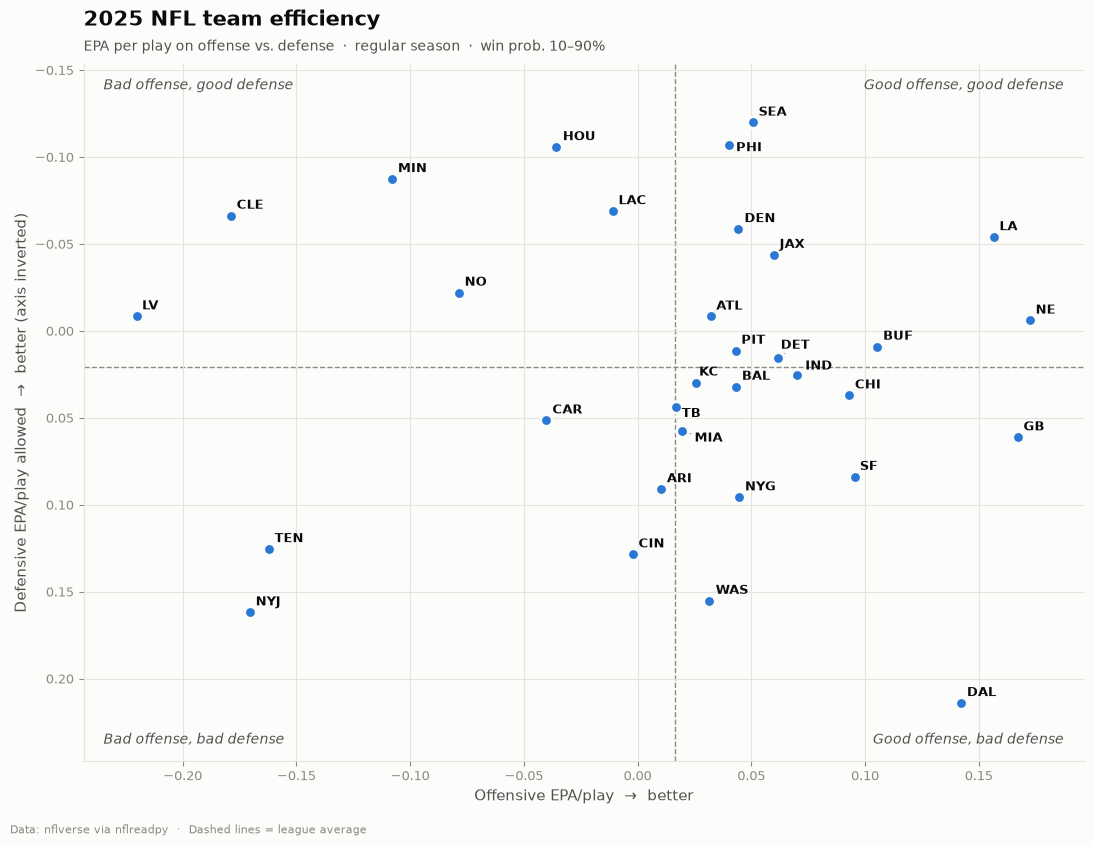

In [4]:
from nfl_analytics import plot_team_efficiency

fig, ax = plot_team_efficiency(
    teams,
    title=f"{SEASON} NFL team efficiency",
    subtitle="EPA per play on offense vs. defense  ·  regular season  ·  win prob. 10–90%",
)

## Ideas to explore next
- Split offense into **pass EPA vs. rush EPA** (`plays[plays['pass'] == 1]`).
- Compare **early-season vs. late-season** efficiency to see who improved.
- Check how well net EPA/play **predicts win totals** (`nflreadpy.load_schedules`).
- Re-run without the garbage-time filter (`offensive_plays(pbp, wp_range=None)`) and see who moves.